## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [3]:
import pickle

with open('./all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Leann Vo

**Date:** 10/19/2026

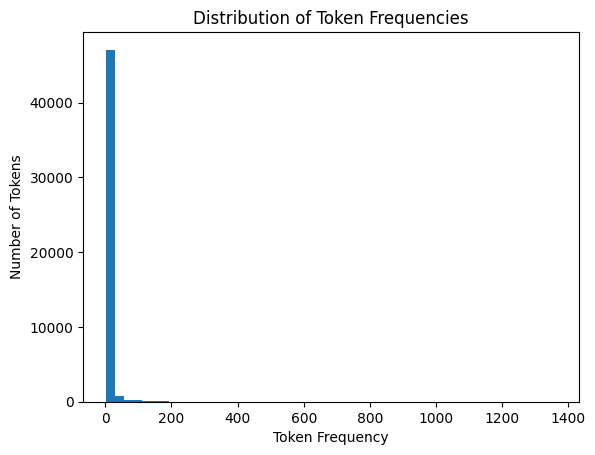

In [4]:
### Question 1:

import pickle

with open('./all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

## 1.1 and 1.2: Plot a histogram of the occurrences of tokens.
import matplotlib.pyplot as plt

frequencies = list(token_count.values())
plt.hist(frequencies, bins=50)
plt.xlabel('Token Frequency')
plt.ylabel('Number of Tokens')
plt.title('Distribution of Token Frequencies')
plt.show()

## 1.3: What do you notice about the frequency of occurrence of different tokens? How does it look?
# The distirbution of tokens is extremely skewed to the right. The majority of tokens only appear a few times while
# a small number of them occur much more frequently. Token occurences are very unevenly distributed.


In [5]:
### Question 2:

## Load Phishing_clean.parquet. This is the text from the e-mails broken into the most common 2,711 tokens and
## one-hot-encoded as features/covariates. So each row is an e-mail, the Email Type takes the value 1 if it's
## a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.
import pandas as pd

df = pd.read_parquet('./Phishing_clean.parquet')
df.head()

## 2.1: Perform an 80/20 train-test split of the data.
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Email Type'])
y = df['Email Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=100
)

print('Training set:', X_train.shape) # 14,907 emails, 2,711 token features
print('Test set:', X_test.shape) # 3,727 emails, 2,711 token features


## 2.2 and 2.3: Run a regression of  𝑦  on the one-hot-encoded emails.
from sklearn.linear_model import LinearRegression

sk_fit = LinearRegression().fit(X_train, y_train)

## 2.4: What is the  𝑅2  on the training set?
print('Training R-squared:', round(sk_fit.score(X_train, y_train), 4))
# R^2 = 0.768 : The model explains about 76.8% of the variation in Email Type within the training set.

## 2.5: 𝑅2 on the test set?
print('Test R-squared:', round(sk_fit.score(X_test, y_test), 4))
# R^2 = 0.6588 : The model explains about 65.88% of the variation in Email Type on unseen data. The lower test R^2 means
# there could be some overfitting.

## 2.6: What words have the largest coefficients in absolute value and most strongly influence predictions?
coeff = pd.Series(sk_fit.coef_, index=X.columns) # pairs coefficient with its token
coeff.reindex(coeff.abs().sort_values(ascending=False).index).head(10) # calc abs value, sort largest to smallest, reindexs
# abs value since 1=spam, 0=not spam

# "background-image" (-0.8915), "localized" (0.8157), "helvetica" (0.7173), and "thermal" (0.7062) had the largest absolute
# coefficients. Positive coefficients like with "localized," "helvetica," and "thermal" increase the predicted phishing
# score, while negative coefficients decrease it. It is interesting that some of the strongest predictors aren't words that
# are typically associated with scams. I'm guessing its because the model found patterns specific to this dataset.


Training set: (14907, 2711)
Test set: (3727, 2711)
Training R-squared: 0.768
Test R-squared: 0.6588


,0
background-image:,-0.891476
localized,0.815698
"helvetica,",0.717349
thermal,0.706216
aging,0.622411
transcript,0.578132
april's,-0.546313
retrieving,-0.527824
cnet,-0.510492
zdnet,-0.503465


Rows and score columns: (18634, 2)
Explained variance: [0.011 0.009]


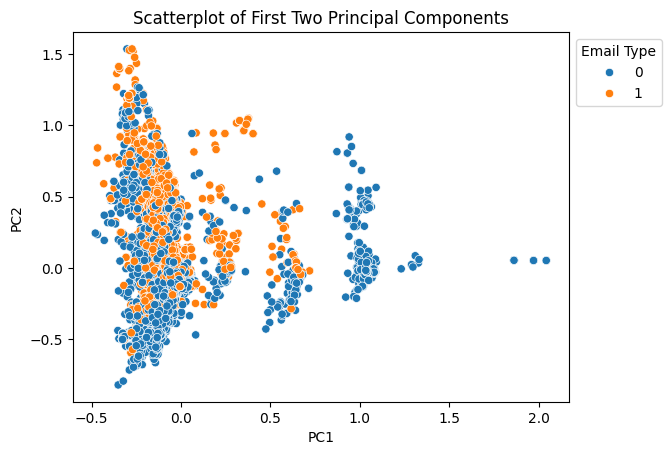

In [6]:
### Question 3:

## 3.1 and 3.2: Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, Email Type) and perform a
## principal components analysis decomposition with two components.
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2)
pca.fit(X)
X_pca = pca.transform(X)

print('Rows and score columns:', X_pca.shape)
print('Explained variance:', pca.explained_variance_ratio_.round(3))


## 3.3, 3.4, 3.5: Plot the first two principal components in a scatter plot and hue the points by whether they are a phishing scam or not.
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values
ax = sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title('Scatterplot of First Two Principal Components')
plt.show()


## 3.6: Do you notice any patterns?
# The first two principal components don't clearly separate the spam and non-spam emails since there is alot of overlap between
# the two groups. However, there are some smaller clusters mostly at higher PC1 values that are mostly non-spam emails. Since the
# first two components only explain about 2% of the total variance, they only show a limited amount of the information in the original data.


In [9]:
### Question 4:

## 4.1 and 4.2: Run a linear regression of  𝑦  on the first 2,610 principal components of  𝑋 .
pca = PCA(n_components=2610)
pca.fit(X)
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

print('Training PCA:', X_train_pca.shape)
print('Testing PCA:', X_test_pca.shape)

sk_fit_pca = LinearRegression().fit(X_train_pca, y_train)

## 4.3 and 4.4: What is the  𝑅2  on the training and test sets?
print('Training R^2:', round(sk_fit_pca.score(X_train_pca, y_train), 4))

print('Test R^2:', round(sk_fit_pca.score(X_test_pca, y_test), 4))


## 4.5: How does this performance compare to the linear regression?
# The PCA regression performed almost the same as the linear regression. Its training R^2 was slightly lower (0.7674 vs.0.7680)
# and its test R^2 was slightly higher (0.6593 vs. 0.6588). This suggests that PCA reduced the number of predictors without
# sacrificing its predictive performance. Although, the improvement in the test R^2 was very small.


Training PCA: (14907, 2610)
Testing PCA: (3727, 2610)
Training R^2: 0.7674
Test R^2: 0.6593


### Question 5:

5.1: Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

PCA helps simplify high-dimensional regression by combining the original data into fewer and uncorrelated components. This reduces overlapping info while still preserving most of the variation in the data. When we used 2,610 components instead of 2,711, it gave us nearly identical R^2 values which proves that we could reduce the numnber of predictors without crazily affecting the performance.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 6c6422b7e864ab1173e55198428c1e342048d634
- **AI tool and model used:** ChatGPT-6

### *Prompts used

1. For my AI assisted revision of my coding assignment, I need you to look over my code compared to the questions being asked. Make a concise numbered list (pastable into colab) of your proposed changes for my answers. Do not be too nitpicky and if you dont have a proposed change then do not mention it.

2. Anymore?

### *AI-proposed changes


1. Question 4: Fit PCA on X_train instead of the entire dataset X. Currently, PCA uses information from the test set before the regression, which introduces data leakage. Change pca.fit(X) to pca.fit(X_train), then transform both the training and test sets as before. Rerun the regression and update the R² values and comparison in Question 4.5 if they change.

2. Question 3.6: Double-check that the first two principal components explain approximately 2% of the total variance using pca.explained_variance_ratio_. If the combined percentage differs, update the explanation to reflect the actual value.

3. Question 5.1: Replace "proves that we could reduce the number of predictors without crazily affecting the performance" with "suggests that we can reduce the number of predictors without substantially affecting predictive performance." This is more accurate because the results support that conclusion for this dataset but do not prove it generally. Update the statement if the corrected PCA regression produces noticeably different R² values.

Overall: The assignment addresses all five questions, and I did not identify other changes necessary from the code and answers provided.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | More accurate R^ values by not using whole dataset|
| 2 | Accept | Double checked |
| 3 | Reject | Wording gets the point across |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

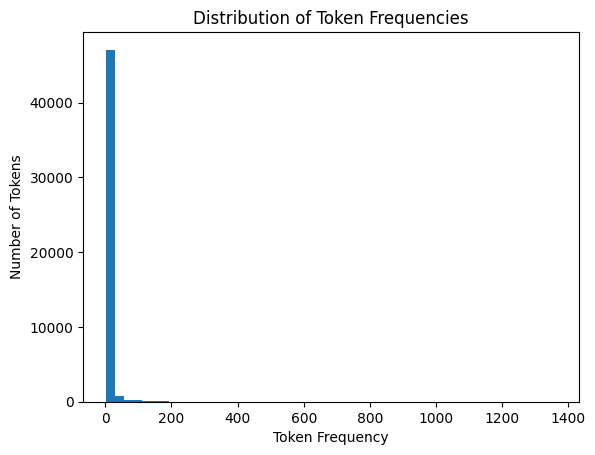

In [ ]:
### Question 1:

import pickle

with open('./all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

## 1.1 and 1.2: Plot a histogram of the occurrences of tokens.
import matplotlib.pyplot as plt

frequencies = list(token_count.values())
plt.hist(frequencies, bins=50)
plt.xlabel('Token Frequency')
plt.ylabel('Number of Tokens')
plt.title('Distribution of Token Frequencies')
plt.show()

## 1.3: What do you notice about the frequency of occurrence of different tokens? How does it look?
# The distirbution of tokens is extremely skewed to the right. The majority of tokens only appear a few times while
# a small number of them occur much more frequently. Token occurences are very unevenly distributed.


In [ ]:
### Question 2:

## Load Phishing_clean.parquet. This is the text from the e-mails broken into the most common 2,711 tokens and
## one-hot-encoded as features/covariates. So each row is an e-mail, the Email Type takes the value 1 if it's
## a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.
import pandas as pd

df = pd.read_parquet('./Phishing_clean.parquet')
df.head()

## 2.1: Perform an 80/20 train-test split of the data.
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Email Type'])
y = df['Email Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=100
)

print('Training set:', X_train.shape) # 14,907 emails, 2,711 token features
print('Test set:', X_test.shape) # 3,727 emails, 2,711 token features


## 2.2 and 2.3: Run a regression of  𝑦  on the one-hot-encoded emails.
from sklearn.linear_model import LinearRegression

sk_fit = LinearRegression().fit(X_train, y_train)

## 2.4: What is the  𝑅2  on the training set?
print('Training R-squared:', round(sk_fit.score(X_train, y_train), 4))
# R^2 = 0.768 : The model explains about 76.8% of the variation in Email Type within the training set.

## 2.5: 𝑅2 on the test set?
print('Test R-squared:', round(sk_fit.score(X_test, y_test), 4))
# R^2 = 0.6588 : The model explains about 65.88% of the variation in Email Type on unseen data. The lower test R^2 means
# there could be some overfitting.

## 2.6: What words have the largest coefficients in absolute value and most strongly influence predictions?
coeff = pd.Series(sk_fit.coef_, index=X.columns) # pairs coefficient with its token
coeff.reindex(coeff.abs().sort_values(ascending=False).index).head(10) # calc abs value, sort largest to smallest, reindexs
# abs value since 1=spam, 0=not spam

# "background-image" (-0.8915), "localized" (0.8157), "helvetica" (0.7173), and "thermal" (0.7062) had the largest absolute
# coefficients. Positive coefficients like with "localized," "helvetica," and "thermal" increase the predicted phishing
# score, while negative coefficients decrease it. It is interesting that some of the strongest predictors aren't words that
# are typically associated with scams. I'm guessing its because the model found patterns specific to this dataset.


Training set: (14907, 2711)
Test set: (3727, 2711)
Training R-squared: 0.768
Test R-squared: 0.6588


,0
background-image:,-0.891476
localized,0.815698
"helvetica,",0.717349
thermal,0.706216
aging,0.622411
transcript,0.578132
april's,-0.546313
retrieving,-0.527824
cnet,-0.510492
zdnet,-0.503465


Rows and score columns: (18634, 2)
Explained variance: [0.011 0.009]


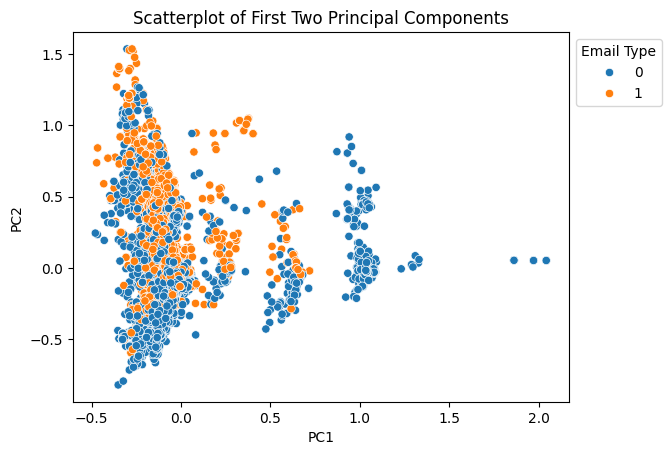

In [ ]:
### Question 3:

## 3.1 and 3.2: Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, Email Type) and perform a
## principal components analysis decomposition with two components.
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2)
pca.fit(X)
X_pca = pca.transform(X)

print('Rows and score columns:', X_pca.shape)
print('Explained variance:', pca.explained_variance_ratio_.round(3))


## 3.3, 3.4, 3.5: Plot the first two principal components in a scatter plot and hue the points by whether they are a phishing scam or not.
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values
ax = sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title('Scatterplot of First Two Principal Components')
plt.show()


## 3.6: Do you notice any patterns?
# The first two principal components don't clearly separate the spam and non-spam emails since there is alot of overlap between
# the two groups. However, there are some smaller clusters mostly at higher PC1 values that are mostly non-spam emails. Since the
# first two components only explain about 2% of the total variance, they only show a limited amount of the information in the original data.


In [10]:
### Question 4:

## 4.1 and 4.2: Run a linear regression of  𝑦  on the first 2,610 principal components of  𝑋 .
pca = PCA(n_components=2610)
pca.fit(X_train)
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

print('Training PCA:', X_train_pca.shape)
print('Testing PCA:', X_test_pca.shape)

sk_fit_pca = LinearRegression().fit(X_train_pca, y_train)

## 4.3 and 4.4: What is the  𝑅2  on the training and test sets?
print('Training R^2:', round(sk_fit_pca.score(X_train_pca, y_train), 4))

print('Test R^2:', round(sk_fit_pca.score(X_test_pca, y_test), 4))


## 4.5: How does this performance compare to the linear regression?
# The PCA regression performed almost the same as the linear regression. Its training R^2 was slightly lower (0.7673 vs.0.7680)
# and its test R^2 was slightly higher (0.6594 vs. 0.6588). This suggests that PCA reduced the number of predictors without
# sacrificing its predictive performance. Although, the improvement in the test R^2 was very small.


Training PCA: (14907, 2610)
Testing PCA: (3727, 2610)
Training R^2: 0.7673
Test R^2: 0.6597


### Question 5:

5.1: Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

PCA helps simplify high-dimensional regression by combining the original data into fewer and uncorrelated components. This reduces overlapping info while still preserving most of the variation in the data. When we used 2,610 components instead of 2,711, it gave us nearly identical R^2 values which proves that we could reduce the numnber of predictors without crazily affecting the performance.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

- The main improvement I made was correcting how PCA performed in Question 4. Originally, I fit PCA on the entire dataset before changing the training and test sets which introduced data leakage. I changed the code to fit PCA only on the training data. After rerunning the regression, the R^2 values changed by less than 0.005 so my overall interpretation stayed the same. I also reviewed explanations to make sure they accurately reflected the results.
- One limitation of the AI feedback was that some suggestions were unnecessary or focused on more minor wording changes than actual problems with the code. For axample, it suggested revising the wording in Question 5 even though my original explanation already addressed the question.
- I verified my final solution by rerunning the code after correcting the PCA step, checked the R^2 values, and reviewed my plots and written answers. My main remaining concern is that using 2,610 principal components only reduced the number of predictors slightly so the practical benefit of PCA on this dataset is limited.